# Objectif 

L'objectif est de comprendre le biais d'environ 67 secondes observé le long de la trajectoire AIS du navire dans le cas active / passive_ais (cf. acouplane_portion5_active_passive_ais_time_bias.ipynb).



**Date de création** : 24/11/2026

In [26]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [27]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from real_data_analysis.acouplane.src.acouplane_cst import (
    ACOUPLANE_PORTION_NC_ROOT_FPATH,
    ACOUPLANE_POSITIONS_NC_FPATH,
    ACOUPLANE_PRESSURE_NC_FPATH,
    AIS_FPATH,
)

from real_data_analysis.acouplane.src.acouplane_plot_mfp import (
    plot_combined_intersection_ambiguity,
    _combined_surfaces_and_positions,
)
from real_data_analysis.acouplane.src.acouplane_plot_portion import (
    plot_portion_tir_pos,
    plot_pressure_section,
    plot_spectrogram_section,
    plot_obs_pos,
)
from real_data_analysis.acouplane.src.acouplane_portion_io import (
    section_name_of,
)

# Chargement des données 

In [28]:
portion_id = 5
# portion_fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
# portion = xr.open_datatree(portion_fpath, auto_complex=True)
# portion

In [29]:
# portion_event_fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
# # portion_event_fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais_single5.nc"

# portion_event = xr.open_datatree(portion_event_fpath, auto_complex=True)
# portion_event

## Données de positions 
Toutes les données disponibles : 

* Données AIS 
* Données de l'ATALANTE 

In [30]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
ds_pos

<xarray.Dataset> Size: 520MB
Dimensions:         (rcv_id: 7, atl_datetime: 563739, mmsi: 521,
                     ais_datetime: 60447, src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2026-03-...
  * mmsi            (mmsi) int64 4kB 4 127 128 129 396 9 ... 480 431 125 32 244
  * ais_datetime    (ais_datetime) datetime64[ns] 484kB 2026-02-23T23:59:50 ....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 5MB ...
    atl_lat         (atl_datetime) float64 5MB ...
    ais_lon         (mmsi, ais_datetime) float64 252MB ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_datetime) float64 269kB ...
    tir_src_lat     (src_datetime) float64 269kB ...
    tir_vessel_lon  (src_datetime) float64 269kB ...
    tir_vessel_lat  (src_datetime) float64 269kB ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

## Données de pression 

In [31]:
ds_pressure = xr.open_dataset(ACOUPLANE_PRESSURE_NC_FPATH)
ds_pressure

<xarray.Dataset> Size: 22GB
Dimensions:         (time_obs1: 996000000, time_obs2: 1000246750,
                     time_obs4: 993600000, time_obs5: 831600000,
                     time_obs6: 819000000, time_obs7: 850177000, obs_id: 6)
Coordinates:
  * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
Dimensions without coordinates: time_obs1, time_obs2, time_obs4, time_obs5,
                                time_obs6, time_obs7
Data variables:
    pressure_obs1   (time_obs1) int32 4GB ...
    pressure_obs2   (time_obs2) int32 4GB ...
    pressure_obs4   (time_obs4) int32 4GB ...
    pressure_obs5   (time_obs5) int32 3GB ...
    pressure_obs6   (time_obs6) int32 3GB ...
    pressure_obs7   (time_obs7) int32 3GB ...
    start_datetime  (obs_id) datetime64[ns] 48B ...
Attributes:
    description:  Données de pression (voie hydro 3)
    campagne:     ACOUPLANE
    fs:           2000
    fullscale:    4.52

# Extraction d'un événement d'intérêt 

In [32]:
event_of_interest = 5
portion_event_fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais_single{event_of_interest}.nc"

portion_eoi = xr.open_datatree(portion_event_fpath, auto_complex=True)
portion_eoi

# portion_eoi = portion_event.match(f"*event_{event_of_interest}")
eoi_name = list(portion_eoi.pressure.children)[0]
portion_eoi

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 1)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 8B ...
│   Attributes:
│       box_lon_min:       5.921525852249999
│       box_lon_max:       5.962816177675
│       box_lat_min:       42.986809747449996
│       box_lat_max:       43.060361284900004
│       portion_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_dat...
├── Group: /position
│   └── Group: /position/event_5
│           Dimensions:         (datetime: 53)
│           Coordinates:
│             * datetime        (datetime) datetime64[ns] 424B 2026-02-28T08:31:10 ... 20...
│           Data variables:
│               lon             (datetime) float64 424B ...
│               lat             (datetime) float64 424B ...
│               start_datetime  datetime64[ns] 8B ...
│               stop_datetime   datetime64[ns] 8B ...
│           Attributes:
│               description:              Positions AIS interpolées
│               interpolation_time_step:  10s
│               campagne:                 ACOUPLANE
│               geodesic_frame:           WGS84
│               event_id:                 5
│               MMSI:                     190
└── Group: /pressure
    └── Group: /pressure/event_5
            Dimensions:         (time_obs1: 1040001, time_obs2: 1040001,
                                 time_obs4: 1040001, time_obs5: 1040001,
                                 time_obs6: 1040001, time_obs7: 1040001, obs_id: 6)
            Coordinates:
              * time_obs1       (time_obs1) datetime64[ns] 8MB 2026-02-28T08:31:10 ... 20...
              * time_obs2       (time_obs2) datetime64[ns] 8MB 2026-02-28T08:31:10 ... 20...
              * time_obs4       (time_obs4) datetime64[ns] 8MB 2026-02-28T08:31:10 ... 20...
              * time_obs5       (time_obs5) datetime64[ns] 8MB 2026-02-28T08:31:10 ... 20...
              * time_obs6       (time_obs6) datetime64[ns] 8MB 2026-02-28T08:31:10 ... 20...
              * time_obs7       (time_obs7) datetime64[ns] 8MB 2026-02-28T08:31:10 ... 20...
              * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
            Data variables:
                pressure_obs1   (time_obs1) float64 8MB ...
                pressure_obs2   (time_obs2) float64 8MB ...
                pressure_obs4   (time_obs4) float64 8MB ...
                pressure_obs5   (time_obs5) float64 8MB ...
                pressure_obs6   (time_obs6) float64 8MB ...
                pressure_obs7   (time_obs7) float64 8MB ...
                start_datetime  (obs_id) datetime64[ns] 48B ...
            Attributes:
                description:  Données de pression (voie hydro 3)
                campagne:     ACOUPLANE
                fs:           2000
                fullscale:    4.52
                event_id:     5

## Spectrogramme

L'événement 5 présente une figure d'interférence caractéristique du passage au CPA sur l'OBS 7. On peut extraire la portion de signal d'intérêt autour de CPA. 

event_5


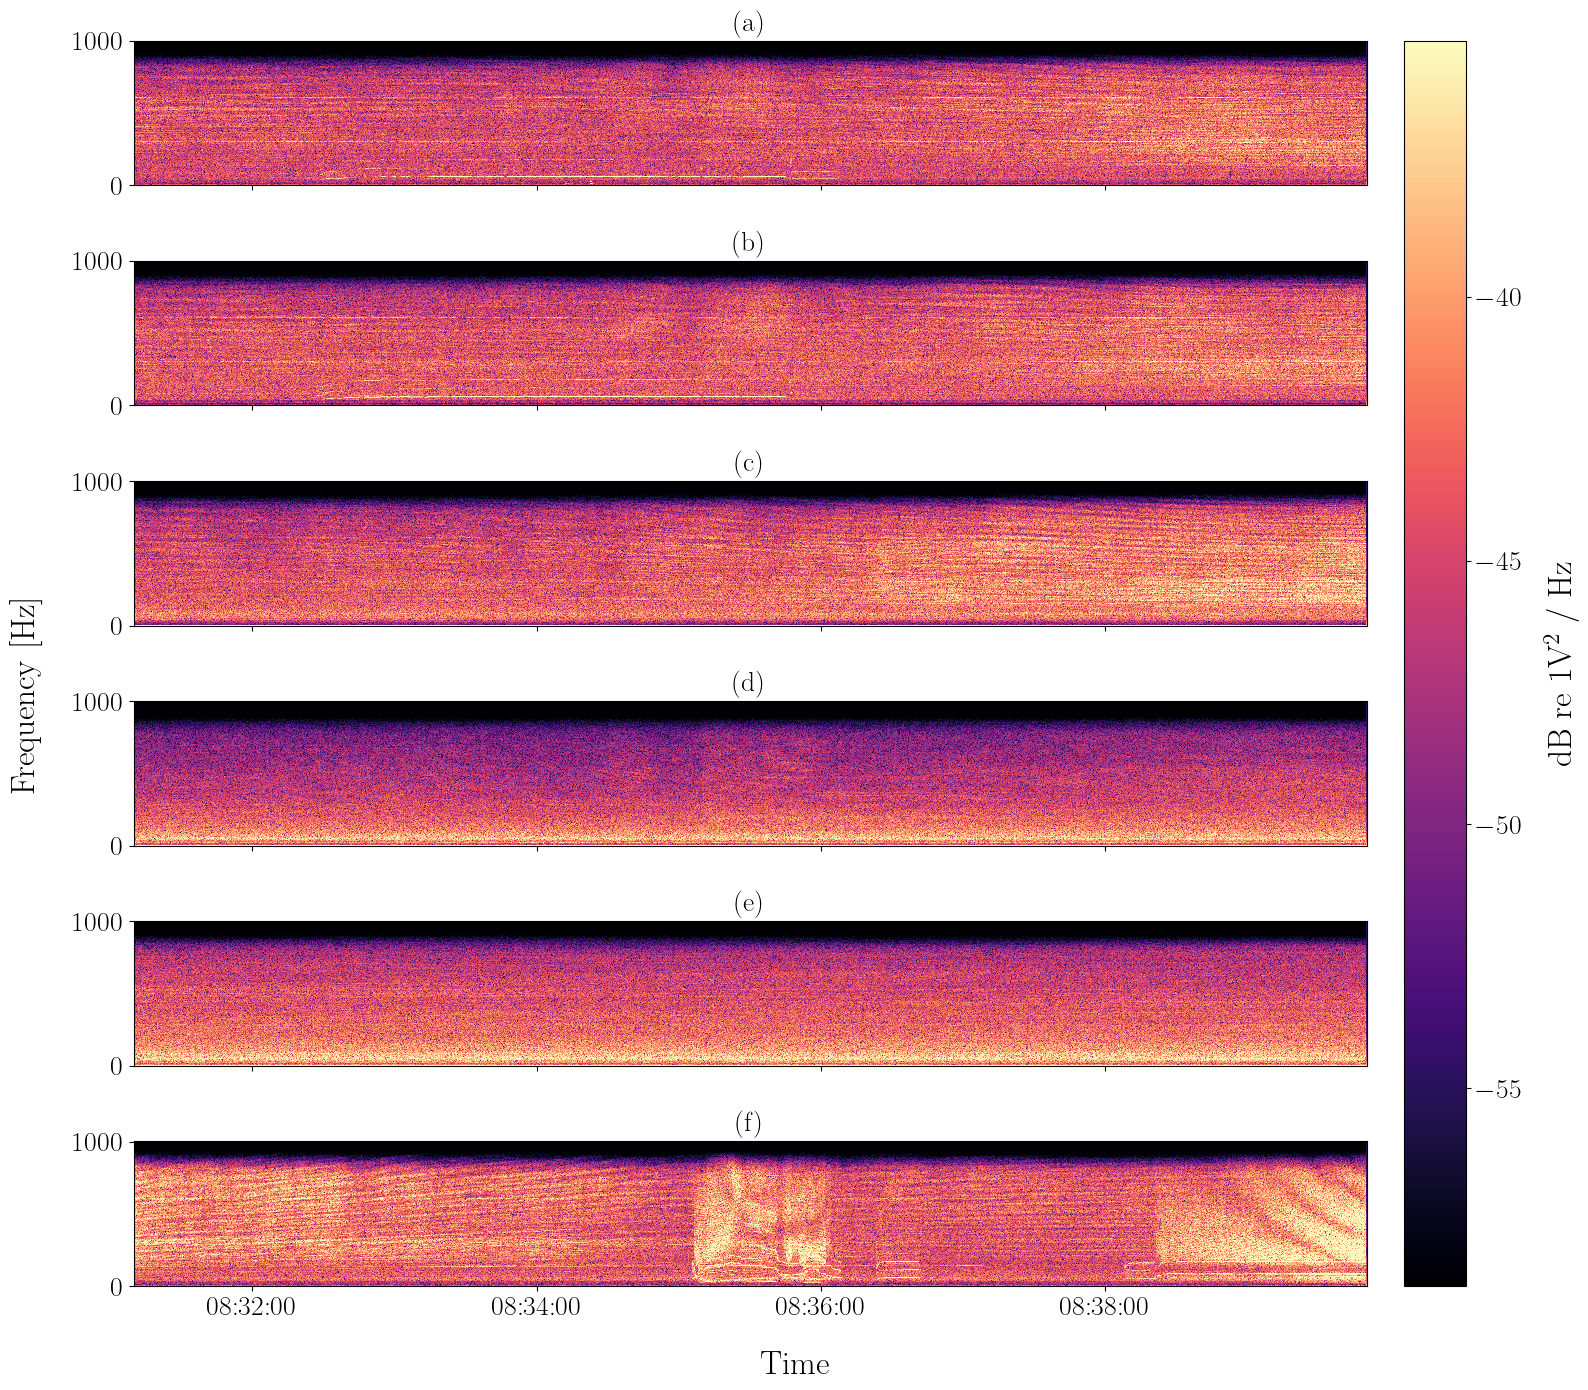

In [33]:
# Plot
for name, node in portion_eoi.pressure.children.items():
    print(name)
    ds_pressure_section = node.to_dataset()
    try:
        fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**10, noverlap=2**9, cmap="magma")
    except:
        print(f"Data with different length event : {name}")
        continue
    # fig.suptitle(f"Event {ds_pressure_section.event_id}")
    # fpath = os.path.join(root_img_spectro, f"spectro_ais_{name}")
    # fig.savefig(fpath)
    # plt.close(fig)
    # plt.show()

## Extraction de la portion de signal autour du CPA

In [34]:
mmsi_eoi = portion_eoi.position[eoi_name].MMSI
eoi_dt0 = portion_eoi.position[eoi_name].datetime.values[0]
eoi_dt0 = pd.to_datetime(eoi_dt0).to_pydatetime()
mmsi_eoi, eoi_dt0

(np.int64(190), datetime.datetime(2026, 2, 28, 8, 31, 10))

In [35]:
duration_eoi_s = 60 * 15
start_dt_eoi = datetime(eoi_dt0.year, eoi_dt0.month, eoi_dt0.day, eoi_dt0.hour, 37, 0)
end_dt_eoi = start_dt_eoi + timedelta(seconds=duration_eoi_s)
start_dt_eoi, end_dt_eoi

(datetime.datetime(2026, 2, 28, 8, 37), datetime.datetime(2026, 2, 28, 8, 52))

In [36]:
ds_pos

<xarray.Dataset> Size: 520MB
Dimensions:         (rcv_id: 7, atl_datetime: 563739, mmsi: 521,
                     ais_datetime: 60447, src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2026-03-...
  * mmsi            (mmsi) int64 4kB 4 127 128 129 396 9 ... 480 431 125 32 244
  * ais_datetime    (ais_datetime) datetime64[ns] 484kB 2026-02-23T23:59:50 ....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 5MB ...
    atl_lat         (atl_datetime) float64 5MB ...
    ais_lon         (mmsi, ais_datetime) float64 252MB ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_datetime) float64 269kB ...
    tir_src_lat     (src_datetime) float64 269kB ...
    tir_vessel_lon  (src_datetime) float64 269kB ...
    tir_vessel_lat  (src_datetime) float64 269kB ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

In [37]:
ds_pos_eoi = ds_pos.sel(ais_datetime=slice(start_dt_eoi, end_dt_eoi)).sel(mmsi=mmsi_eoi)
ds_pos_eoi = ds_pos_eoi.sel(atl_datetime=slice(start_dt_eoi, end_dt_eoi))
ds_pos_eoi

<xarray.Dataset> Size: 2MB
Dimensions:         (rcv_id: 7, atl_datetime: 879, ais_datetime: 91,
                     src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 7kB 2026-02-28T08:37:00.000...
  * ais_datetime    (ais_datetime) datetime64[ns] 728B 2026-02-28T08:37:00 .....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
    mmsi            int64 8B 190
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 7kB ...
    atl_lat         (atl_datetime) float64 7kB ...
    ais_lon         (ais_datetime) float64 728B ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_datetime) float64 269kB ...
    tir_src_lat     (src_datetime) float64 269kB ...
    tir_vessel_lon  (src_datetime) float64 269kB ...
    tir_vessel_lat  (src_datetime) float64 269kB ...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

In [38]:
from real_data_analysis.acouplane.src.acouplane_utils import (
    plot_obs_pos,
    extract_pressure_section,
    convert_raw_pressure_to_physical_units,
)

In [39]:
ds_pressure_eoi_i = extract_pressure_section(
    start_dt_eoi,
    end_dt_eoi,
    ds_pressure,
    obs_datetimes=None,
)
ds_pressure_eoi = convert_raw_pressure_to_physical_units(ds_pressure=ds_pressure_eoi_i)
ds_pressure_eoi_i

<xarray.Dataset> Size: 173MB
Dimensions:         (time_obs1: 1800001, time_obs2: 1800001,
                     time_obs4: 1800001, time_obs5: 1800001,
                     time_obs6: 1800001, time_obs7: 1800001, obs_id: 6)
Coordinates:
  * time_obs1       (time_obs1) datetime64[ns] 14MB 2026-02-28T08:37:00 ... 2...
  * time_obs2       (time_obs2) datetime64[ns] 14MB 2026-02-28T08:37:00 ... 2...
  * time_obs4       (time_obs4) datetime64[ns] 14MB 2026-02-28T08:37:00 ... 2...
  * time_obs5       (time_obs5) datetime64[ns] 14MB 2026-02-28T08:37:00 ... 2...
  * time_obs6       (time_obs6) datetime64[ns] 14MB 2026-02-28T08:37:00 ... 2...
  * time_obs7       (time_obs7) datetime64[ns] 14MB 2026-02-28T08:37:00 ... 2...
  * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
Data variables:
    pressure_obs1   (time_obs1) float64 14MB 0.02926 0.02868 ... 0.02921 0.03223
    pressure_obs2   (time_obs2) float64 14MB 0.02779 0.02787 ... 0.02854 0.02452
    pressure_obs4   (time_obs4) float64 14MB 0.02625 0.03369 ... 0.0294 0.03005
    pressure_obs5   (time_obs5) float64 14MB 0.02396 0.02455 ... 0.02818 0.02714
    pressure_obs6   (time_obs6) float64 14MB 0.03226 0.03007 ... 0.03251 0.03172
    pressure_obs7   (time_obs7) float64 14MB 0.03129 0.02902 ... 0.0251 0.03115
    start_datetime  (obs_id) datetime64[ns] 48B ...
Attributes:
    description:  Données de pression (voie hydro 3)
    campagne:     ACOUPLANE
    fs:           2000
    fullscale:    4.52

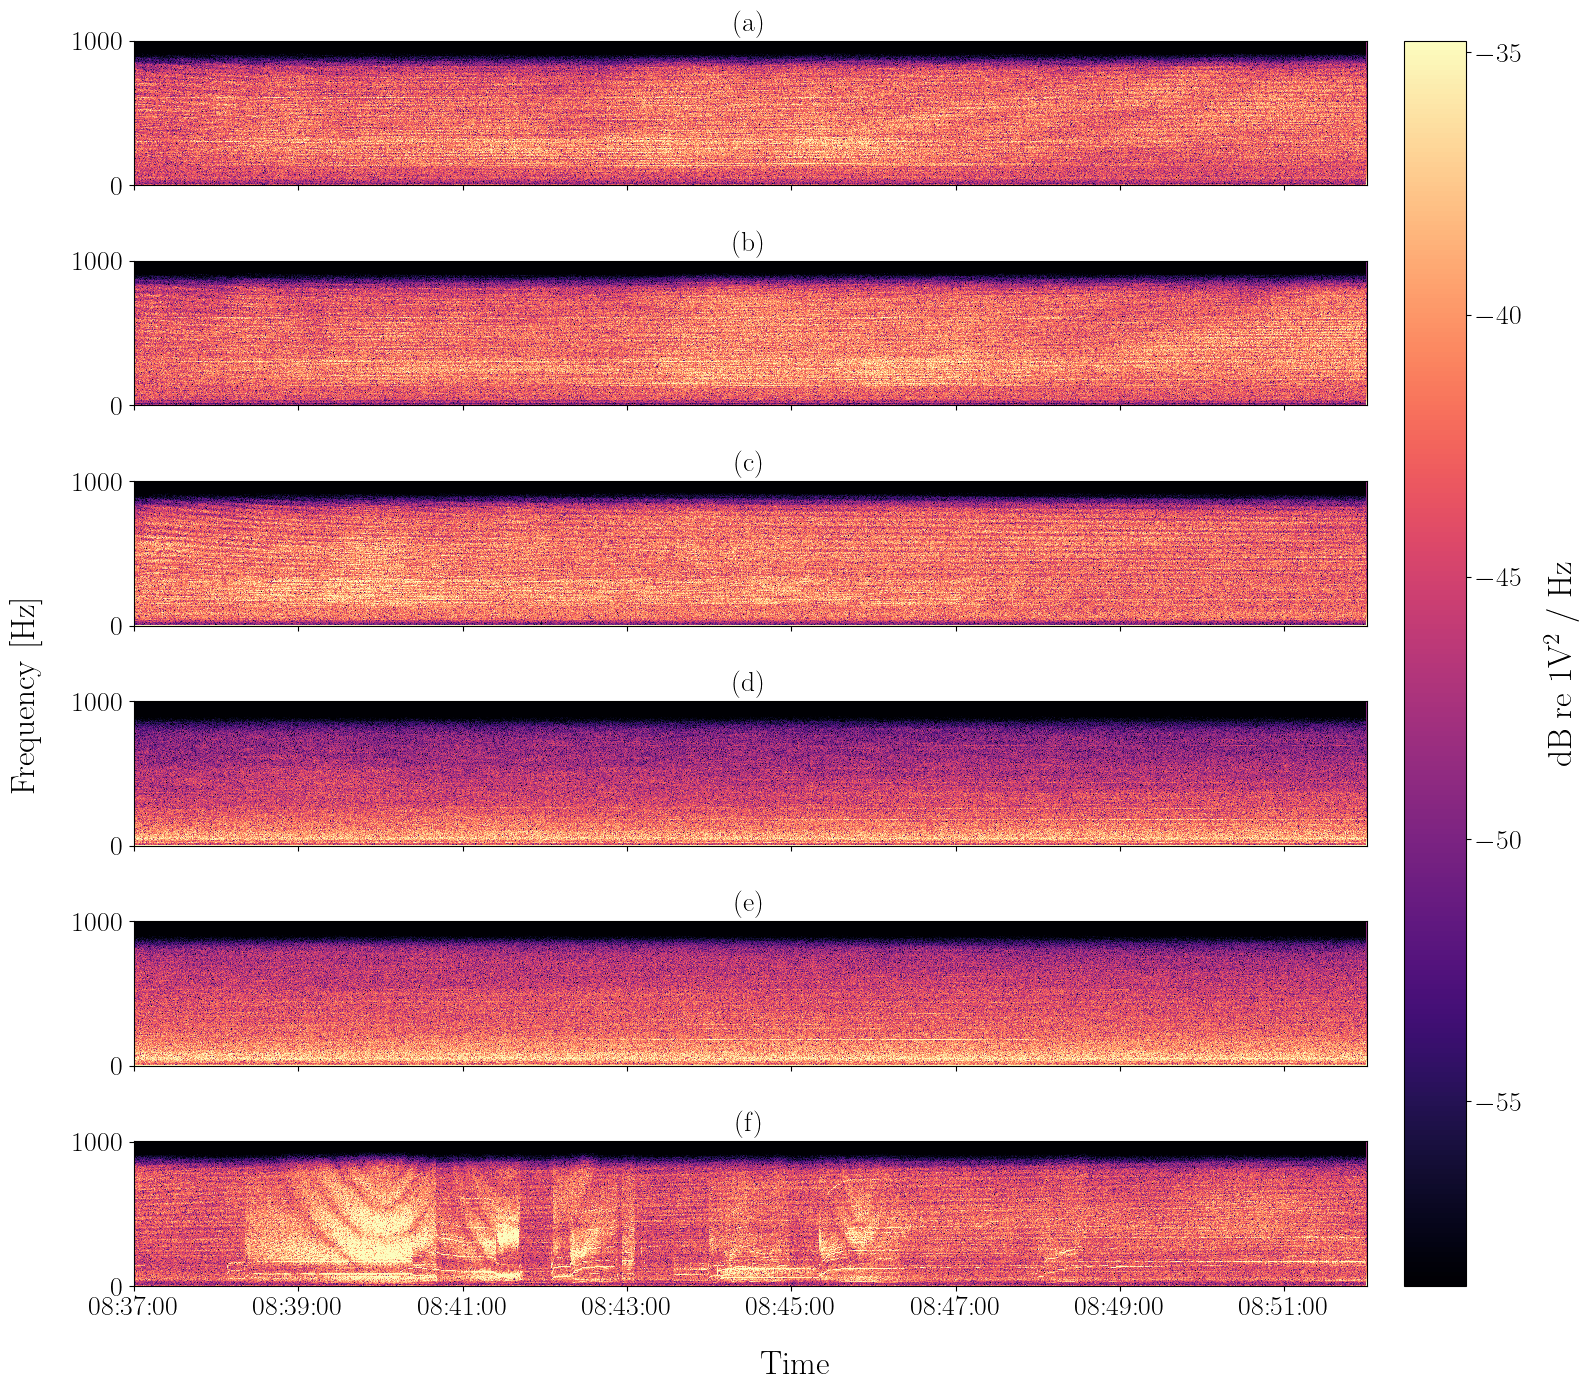

In [40]:
fig, axs = plot_spectrogram_section(ds_pressure_eoi, nperseg=2**10, noverlap=2**9, cmap="magma")

# Illustration du biais 

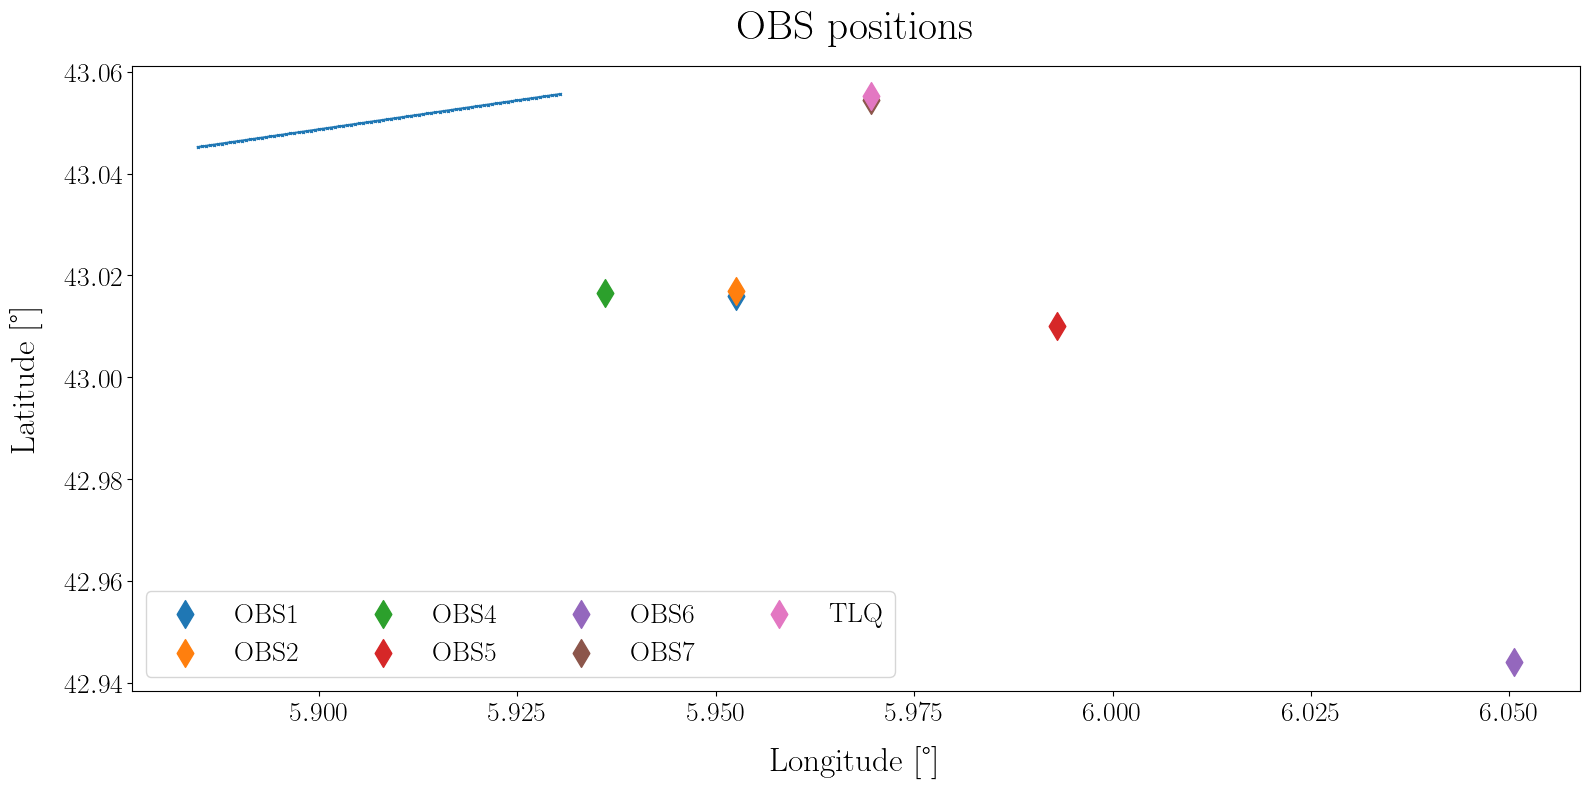

In [41]:
# Plot
fig, ax = plt.subplots(figsize=(16, 8))
plot_obs_pos(ds_pos_eoi, ax=ax)

plt.plot(
    ds_pos_eoi.ais_lon,
    ds_pos_eoi.ais_lat,
    "-x",
    markersize=2,
    # label=f"Event {ds_pos_eoi.event_id}",
)


## Calcul distance dans l'espace -> CPA théorique 

In [17]:
def get_dist_src_rcv(src_lon, src_lat, rcv_lon, rcv_lat):
    from pyproj import Geod

    geod = Geod(ellps="WGS84")

    # Cast the rcv position to the shape of the src positions
    lon_rcv = np.full(src_lon.size, rcv_lon)
    lat_rcv = np.full(src_lat.size, rcv_lat)

    # Compute geodesic distance
    _, _, horizontal_distance = geod.inv(
        lons1=src_lon, lats1=src_lat, lons2=lon_rcv, lats2=lat_rcv
    )

    return horizontal_distance


def get_distance_src_to_rcv(ds_pos_eoi):
    # Library
    ais_lon = ds_pos_eoi.ais_lon.values
    ais_lat = ds_pos_eoi.ais_lat.values

    dist_ais_rcv = []
    for rcv_id in ds_pos_eoi.rcv_id.values:

        rcv_lon_i = ds_pos_eoi.rcv_lon.sel(rcv_id=rcv_id)
        rcv_lat_i = ds_pos_eoi.rcv_lat.sel(rcv_id=rcv_id)

        d_ais_rcv = get_dist_src_rcv(ais_lon, ais_lat, rcv_lon_i, rcv_lat_i)

        dist_ais_rcv.append(d_ais_rcv)

    ds_pos_eoi["distance_ais_rcv"] = (
        ["rcv_id", "ais_datetime"],
        np.asarray(dist_ais_rcv),
    )

In [18]:
get_distance_src_to_rcv(ds_pos_eoi=ds_pos_eoi)
ds_pos_eoi

<xarray.Dataset> Size: 2MB
Dimensions:           (rcv_id: 7, atl_datetime: 241, ais_datetime: 25,
                       src_datetime: 33608)
Coordinates:
  * rcv_id            (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime      (atl_datetime) datetime64[ns] 2kB 2026-02-28T08:37:00.0...
  * ais_datetime      (ais_datetime) datetime64[ns] 200B 2026-02-28T08:37:00 ...
  * src_datetime      (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06...
    mmsi              int64 8B 190
Data variables: (12/14)
    rcv_lon           (rcv_id) float64 56B ...
    rcv_lat           (rcv_id) float64 56B ...
    rcv_immersion     (rcv_id) int16 14B ...
    atl_lon           (atl_datetime) float64 2kB ...
    atl_lat           (atl_datetime) float64 2kB ...
    ais_lon           (ais_datetime) float64 200B 5.93 5.93 ... 5.919 5.918
    ...                ...
    tir_ECOS          (src_datetime) int64 269kB ...
    tir_src_lon       (src_datetime) float64 269kB ...
    tir_src_lat       (src_datetime) float64 269kB ...
    tir_vessel_lon    (src_datetime) float64 269kB ...
    tir_vessel_lat    (src_datetime) float64 269kB ...
    distance_ais_rcv  (rcv_id, ais_datetime) float64 1kB 4.759e+03 ... 4.185e+03
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

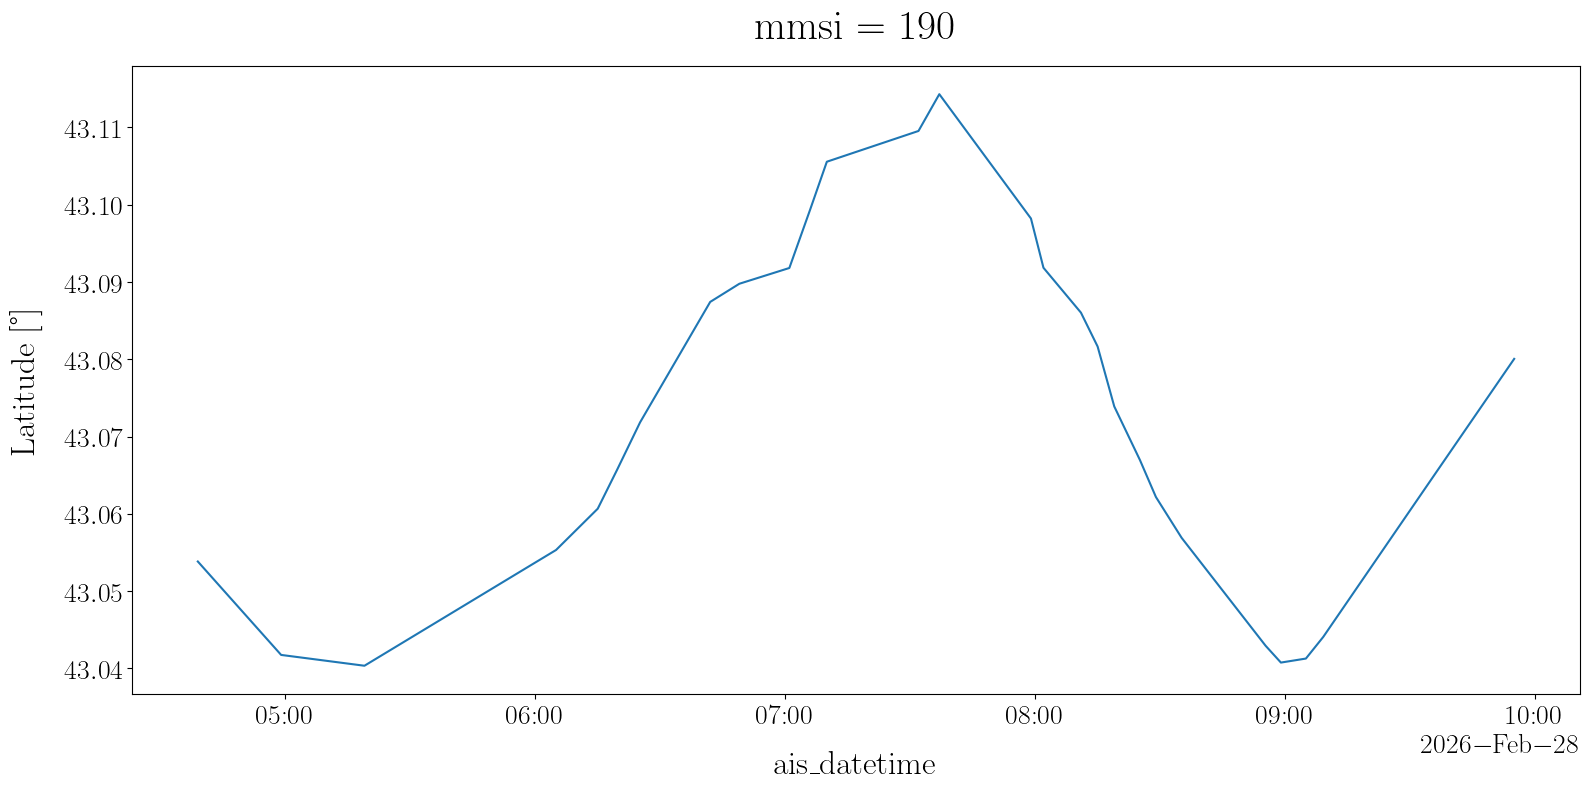

In [22]:
ds_pos.sel(mmsi=mmsi_eoi).ais_lat.plot()

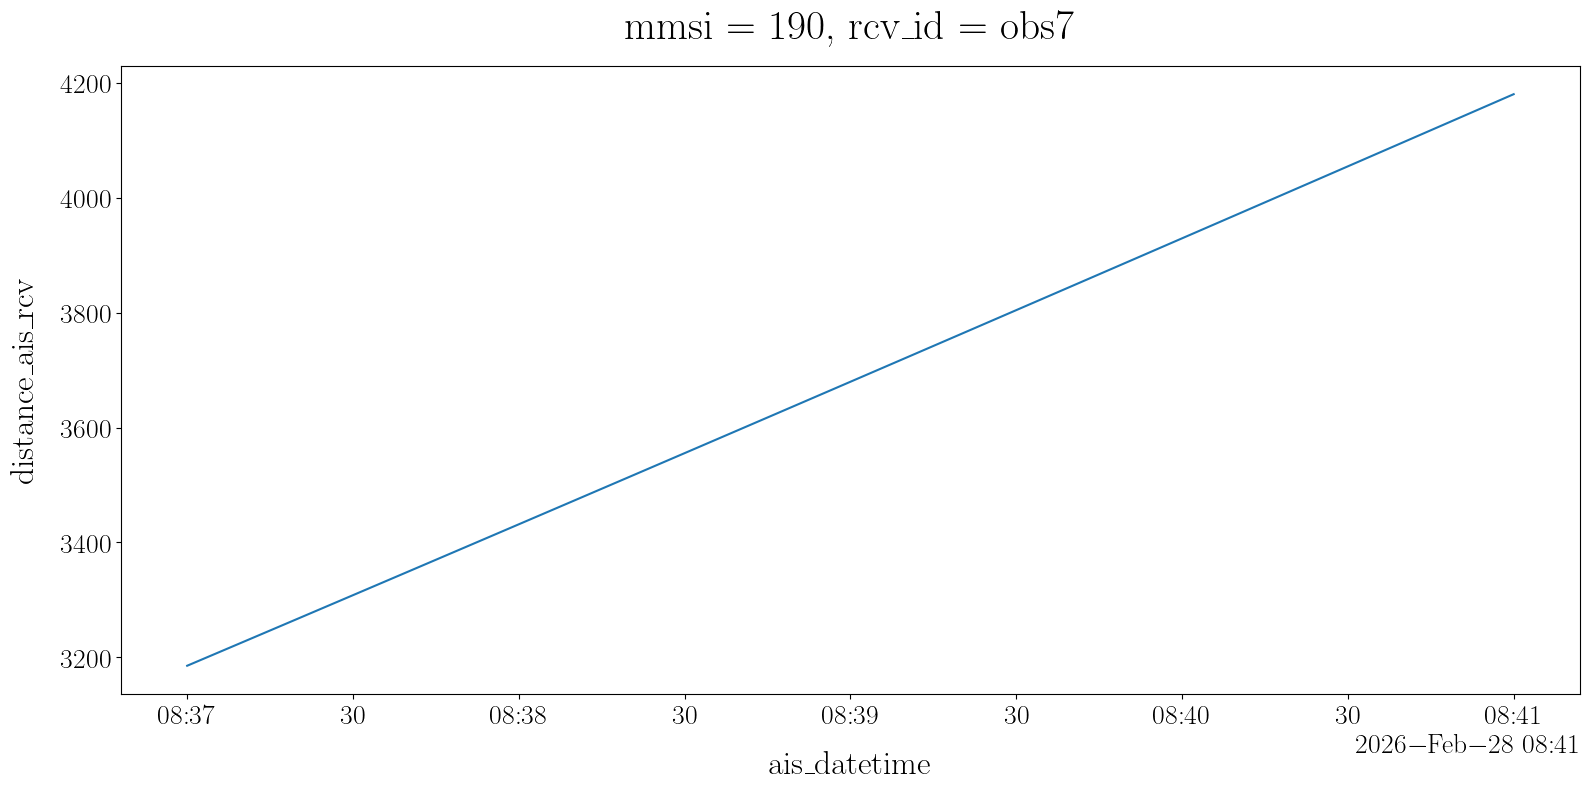

In [21]:
# fig, axs = plt.subplots(2, 1, figsize=(16, 12), sharey=True)

ds_pos_eoi.distance_ais_rcv.sel(rcv_id="obs7").plot(x="ais_datetime", hue="rcv_id")

## Une intersection 

### Paramètres 

In [ ]:
event = "event_28"
library0 = "sn2"
metric = "theta_gamma_centered"
rcv_combination = ["obs2", "obs4"]
combination_method = "mean_surfaces"
ambiguity_cmap = "Grays_r"
ambiguity_max_quantile = (
    0.95  # quantile of each feature distance used as upper bound of its color scale
)
ambiguity_d_real_vmax = 100  # upper bound of the color scale of the real distance [m]
ambiguity_metrics = ["theta_gamma_centered", "L2_gamma_centered", "dcf"]

### Surface d'ambiguïté 

In [ ]:
ds_mfp = portion_ais_mfp.mfp_intersection[library0][event]
library_display_name = f"library {section_name_of(portion.position[library0])}"
event_attrs = portion_event.position[event].to_dataset().attrs
event_display_name = f"event {event_attrs.get('event_id', event)}"
library_display_name, event_display_name

In [ ]:
fig = plot_combined_intersection_ambiguity(
    ds_mfp,
    rcv_combination,
    library_display_name,
    event_display_name,
    method=combination_method,
    cmap=ambiguity_cmap,
    max_quantile=ambiguity_max_quantile,
    metrics=ambiguity_metrics,
    d_real_vmax=ambiguity_d_real_vmax,
)

### Biais 

In [ ]:
ds_combined, target_dt, guess_dt = _combined_surfaces_and_positions(
    ds_mfp, rcv_combination=rcv_combination, method=combination_method
)
# Target
target_dt_lib, target_dt_event = target_dt 
print(
    f"Target intersection datetime : \n\t Along library {target_dt_lib} \n\t Along event {target_dt_event}"
)
# Guess
guess_dt_lib, guess_dt_event = guess_dt[metric]
print(
    f"Guess intersection datetime : \n\t Along library {guess_dt_lib} \n\t Along event {guess_dt_event}"
)
err_time_along_lib_ns = target_dt_lib - guess_dt_lib
err_time_along_lib_s = err_time_along_lib_ns / np.timedelta64(1, "s")
err_time_along_event_ns = target_dt_event - guess_dt_event
err_time_along_event_s = err_time_along_event_ns / np.timedelta64(1, "s")
print(
    f"Error time along library = {err_time_along_lib_s} s \nError time along event = {err_time_along_event_s}s"
)


## L'ensemble des intersections 

### Sélection des sections de la librairie dans l'ordre de croisement avec l'event 3 

In [ ]:
# Plot
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (portion_event.box_lon_min, portion_event.box_lat_min),
        portion_event.box_lon_max - portion_event.box_lon_min,
        portion_event.box_lat_max - portion_event.box_lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)

for name, node in portion_event.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.lon, ds_position_section.lat, "-x", markersize=2, label=f"Event {ds_position_section.event_id}"
    )

ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

In [ ]:
library_sections = [
    "sn0",
    "oe6",
    "sn2",
    "oe5",
    "sn1",
    "oe4",
    "sn3",
]
n_library = len(library_sections)

### Calcul de l'ensemble des surfaces d'ambiguïté 

In [ ]:
# Dedicated arrays (one element per library section)
target_dt_lib_arr = np.full(n_library, np.datetime64("NaT"), dtype="datetime64[ns]")
target_dt_event_arr = np.full(n_library, np.datetime64("NaT"), dtype="datetime64[ns]")
guess_dt_lib_arr = np.full(n_library, np.datetime64("NaT"), dtype="datetime64[ns]")
guess_dt_event_arr = np.full(n_library, np.datetime64("NaT"), dtype="datetime64[ns]")
err_time_along_lib_s_arr = np.full(n_library, np.nan)
err_time_along_event_s_arr = np.full(n_library, np.nan)

# 1) Combine the surfaces of every library section and store the target / guess positions
combined = {}
for il, library in enumerate(library_sections):
    ds_mfp = portion_ais_mfp.mfp_intersection[library][event]
    ds_combined, target_dt, guess_dt = _combined_surfaces_and_positions(
        ds_mfp, rcv_combination=rcv_combination, method=combination_method
    )
    combined[library] = ds_combined

    # Target
    target_dt_lib, target_dt_event = target_dt
    # print(
    #     f"[{library}] Target intersection datetime : \n\t Along library {target_dt_lib} \n\t Along event {target_dt_event}"
    # )
    target_dt_lib_arr[il] = target_dt_lib
    target_dt_event_arr[il] = target_dt_event

    # Guess
    guess_dt_lib, guess_dt_event = guess_dt[metric]
    # print(
    #     f"[{library}] Guess intersection datetime : \n\t Along library {guess_dt_lib} \n\t Along event {guess_dt_event}"
    # )
    guess_dt_lib_arr[il] = guess_dt_lib
    guess_dt_event_arr[il] = guess_dt_event

    err_time_along_lib_ns = target_dt_lib - guess_dt_lib
    err_time_along_lib_s_arr[il] = err_time_along_lib_ns / np.timedelta64(1, "s")
    err_time_along_event_ns = target_dt_event - guess_dt_event
    err_time_along_event_s_arr[il] = err_time_along_event_ns / np.timedelta64(1, "s")

In [ ]:
x_dim = "library_datetime"

# 2) Common color scale of the metric column (real distance: fixed scale)
d_real_vmin, d_real_vmax = 0, 200
all_values = np.concatenate(
    [ds[f"d_{metric}"].values.ravel() for ds in combined.values()]
)
all_values = all_values[np.isfinite(all_values)]
metric_vmin = all_values.min()
metric_vmax = np.quantile(all_values, ambiguity_max_quantile)

# 3) Figure: the x axis (library datetimes) differs between sections -> sharex=False
fig, axs = plt.subplots(
    n_library,
    2,
    figsize=(16, 16),
    sharex=False,
    sharey=True,
    layout="constrained",
)
axs = np.atleast_2d(axs)

for il, library in enumerate(library_sections):
    ds_combined = combined[library]

    # add_colorbar=False: a single colorbar per column is added below
    mesh_real = ds_combined.d_real.plot(
        x=x_dim,
        cmap=ambiguity_cmap,
        ax=axs[il, 0],
        vmin=d_real_vmin,
        vmax=d_real_vmax,
        add_colorbar=False,
    )
    mesh_metric = ds_combined[f"d_{metric}"].plot(
        x=x_dim,
        cmap=ambiguity_cmap,
        ax=axs[il, 1],
        vmin=metric_vmin,
        vmax=metric_vmax,
        add_colorbar=False,
    )

    # Target position on both columns (x: along library, y: along event)
    if not np.isnat(target_dt_lib_arr[il]):
        for ax in axs[il]:
            ax.scatter(
                target_dt_lib_arr[il],
                target_dt_event_arr[il],
                marker="s",
                s=400,
                facecolors="none",
                edgecolors="r",
                linewidth=3,
                label="Target",
            )

    # Guess position on the metric column only
    if not np.isnat(guess_dt_lib_arr[il]):
        axs[il, 1].scatter(
            guess_dt_lib_arr[il],
            guess_dt_event_arr[il],
            marker="o",
            s=200,
            facecolors="none",
            edgecolors="m",
            linewidth=3,
            label="Guess",
        )

    # Section name on the left, no titles nor axis labels on the panels
    axs[il, 0].set_ylabel(library)
    axs[il, 1].set_ylabel("")
    for ax in axs[il]:
        ax.set_xlabel("")
        ax.set_title("")

# Legend once (first row)
axs[0, 0].legend(loc="upper right")
axs[0, 1].legend(loc="upper right")


# 4) One horizontal colorbar above each column (label = name and unit of the variable)
def colorbar_label(da):
    label = da.attrs.get("long_name", da.name)
    if "units" in da.attrs:
        label += f" [{da.attrs['units']}]"
    return label


last = combined[library_sections[-1]]
for column, (mesh, da) in enumerate(
    [(mesh_real, last.d_real), (mesh_metric, last[f"d_{metric}"])]
):
    cbar = fig.colorbar(
        mesh,
        ax=axs[:, column],
        location="top",
        orientation="horizontal",
        shrink=0.8,
        aspect=40,
    )
    cbar.set_label(colorbar_label(da))

## Biais observé

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
axs[0].plot(library_sections, err_time_along_lib_s_arr, label="Along library", marker="o")
axs[1].plot(library_sections, err_time_along_event_s_arr, label="Along event", marker="o")
fig.supylabel("Time to target [s]")
fig.supxlabel("Library section")
axs[0].legend()
axs[1].legend()

In [ ]:
err_time_along_lib_s_mean = np.mean(err_time_along_lib_s_arr)
err_time_along_event_s_mean = np.mean(err_time_along_event_s_arr)
print(f"Mean err along library {err_time_along_lib_s_mean} s")
print(f"Mean err along event {err_time_along_event_s_mean} s")

# Vérification position ATL 

On peut vérifier que la source de l'event 3 ne correspond pas à l'ATALANTE en transit dans la zone 

In [ ]:
ds_pos_event = portion_event.position[event].to_dataset()
ds_pos_event

In [ ]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
ds_pos

In [ ]:
ds_pos = ds_pos.sel(
    atl_datetime=slice(ds_pos_event.datetime.min(), ds_pos_event.datetime.max())
)
ds_pos = ds_pos.sel(
    src_datetime=slice(ds_pos_event.datetime.min(), ds_pos_event.datetime.max())
)

In [ ]:
fig, ax = plt.subplots()

dates = ds_pos.atl_datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos.atl_lon,
    ds_pos.atl_lat,
    c=date_num,
    cmap="magma",
)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("ATL datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))


dates = ds_pos_event.datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos_event.lon,
    ds_pos_event.lat,
    c=date_num,
    cmap="jet",
)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Event datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

plot_obs_pos(ds_pos, ax=ax)

# Lien potentiel avec la taille du navire 

Ce biais peut être dû à la taille du navire. Si l'on considère que la source du navire est une source ponctuelle située au niveau de l'hélice du navire, il existe un bras de levier important entre l'antenne AIS du navire généralement situé à l'avant du navire et l'hélice à l'arrière du navire. Pour de gros navires, des portes conteneurs par exemple, ce bras de levier peut être de l'ordre de 100 à 300 voir 400 mètres et pourrait expliquer le biais observé. 

## Vitesse d'avance du navire 

In [ ]:
from pyproj import Geod

geod = Geod(ellps="WGS84")

src_lon1, src_lat1 = (
    ds_pos_event.lon,
    ds_pos_event.lat,
)

# Traj 1
lon1_a = src_lon1.values[:-1]
lat1_a = src_lat1.values[:-1]
lon1_b = src_lon1.values[1:]
lat1_b = src_lat1.values[1:]

_, _, dist_11 = geod.inv(lons1=lon1_a, lats1=lat1_a, lons2=lon1_b, lats2=lat1_b)
speed_1 = dist_11 / np.diff(src_lon1.datetime.values).astype("timedelta64[s]").astype(
    float
)

In [ ]:
im = plt.plot(src_lon1.datetime[:-1], speed_1, color="k")
plt.ylabel("Speed [m/s]")

Vs = np.nanmedian(speed_1)
print(
    f"Median speed along {event} trajectory: {Vs:.2f} m/s"
)
for dt in target_dt_event_arr:
    plt.axvline(dt)

Connaissant la vitesse d'avance moyenne du navire on peut en déduire l'erreur en distance $\Delta L$ associée à l'erreur $\Delta t$ (le biais) mesurée sur le temps le long de l'event 3 : 

$$
\Delta L = V_s \times \Delta t  
$$





In [ ]:
delta_t_ev = err_time_along_event_s_mean
delta_L_ev = Vs * delta_t_ev 
print(f"Delta L (event) = {delta_L_ev} m")

# Vérification des positions AIS interpolées 

In [ ]:
def load_ais():
    df_ais = pd.read_csv(
        AIS_FPATH,
        delimiter=";",
        header=0,
        names=["mmsi", "datetime", "lon", "lat"],
    )
    # Convert datatime columns from str to datetime
    fmt = "%d/%m/%Y %H:%M"
    df_ais["datetime"] = pd.to_datetime(df_ais["datetime"], format=fmt)
    # Change dtypes
    df_ais["mmsi"] = df_ais["mmsi"].astype(int)

    # Remove AIS lines with unique positions (at least two points to define a trajectory)
    df_ais = df_ais.groupby("mmsi").filter(lambda x: len(x) > 1)

    # Remove duplicates if any
    df_ais = df_ais.drop_duplicates()

    # Sort 

    return df_ais

In [ ]:
df_ais = load_ais()
df_ais

In [ ]:
ds_pos_event

In [ ]:
import pandas as pd

# Reference datetime
target_datetime = pd.Timestamp(ds_pos_event.datetime.values[0])

# Ensure datetime format
df_ais["datetime"] = pd.to_datetime(df_ais["datetime"])

# Calculate absolute time difference
df_ais["time_diff"] = (df_ais["datetime"] - target_datetime).abs()

# Find the 10 closest distinct MMSI
closest_mmsi = (
    df_ais.sort_values("time_diff")
    .drop_duplicates(subset="mmsi", keep="first")
    .head(10)
    .reset_index(drop=True)
)

print(closest_mmsi[["mmsi", "datetime", "time_diff", "lon", "lat"]])

In [ ]:
# Select raw ais data for event
# df_ais_event = df_ais.loc[df_ais["mmsi"] == ds_pos_event.MMSI]
df_ais_event = df_ais.loc[df_ais["mmsi"] == 346]

# Select period of interest
df_ais_event = df_ais_event.loc[
    (df_ais_event["datetime"] >= ds_pos_event.datetime.min().values)
    & (df_ais_event["datetime"] <= ds_pos_event.datetime.max().values)
]

df_ais_event

In [ ]:
fig, ax = plt.subplots()

dates = df_ais_event.datetime.values
date_num = mdates.date2num(dates)

ax.plot(
    df_ais_event.lon,
    df_ais_event.lat,
    marker="x",
    color="k",
    markersize=10,
    # c=date_num,
    # cmap="magma",
)

dates = ds_pos_event.datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos_event.lon,
    ds_pos_event.lat,
    c=date_num,
    cmap="jet",
)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Event datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

# plot_obs_pos(ds_pos, ax=ax)

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axs[0].plot(
    df_ais_event.datetime,
    df_ais_event.lon,
    # df_ais_event.lat,
    marker="x",
    color="k",
    markersize=10,
    # c=date_num,
    # cmap="magma",
)
axs[0].scatter(
    ds_pos_event.datetime,
    ds_pos_event.lon,
    # ds_pos_event.lat,
    c=date_num,
    cmap="jet",
)
axs[1].plot(
    df_ais_event.datetime,
    # df_ais_event.lon,
    df_ais_event.lat,
    marker="x",
    color="k",
    markersize=10,
    # c=date_num,
    # cmap="magma",
)
axs[1].scatter(
    ds_pos_event.datetime,
    # ds_pos_event.lon,
    ds_pos_event.lat,
    c=date_num,
    cmap="jet",
)
axs[0].set_ylabel("Longitude [°]")
axs[1].set_ylabel("Latitude [°]")

fig.supxlabel("Time")

In [ ]:
ds_pos_event.lat.drop_duplicates(dim="datetime")